# Gym member segments: who should get the monthly offer?

k-means clustering of gym members into segments, used to decide which segments get the $10 extras credit.
Running this notebook top to bottom reproduces every number and chart in the slides.

Steps: (1) 70/30 split, (2) scale on training members, fit k-means for k = 1 to 8, pick k from the elbow,
(3) check the elbow on test members without refitting, (4) credit decision and new-member function, (5) monthly value.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

pd.set_option("display.width", 200)
SEED = 42
K_CHOSEN = 4

# Finance's assumptions
CREDIT_COST = 10        # every member who gets the credit uses it
SPEND_CUTOFF = 20       # $20+/month on extras: would spend the same anyway
NET_HIGH_SPENDER = -10  # credit is a pure giveaway
NET_LOW_SPENDER = 15 - CREDIT_COST   # spends $25 more at 60% margin = $15, minus the $10 credit = +$5

gym = pd.read_csv("data/gym_members.csv")
print(f"Rows: {len(gym)}, columns: {gym.shape[1]}, missing values: {gym.isna().sum().sum()}")
print(f"Average extras spend: ${gym['monthly_extras_spend'].mean():.2f} a month")
print(f"Members spending $20+ on extras: {(gym['monthly_extras_spend'] >= SPEND_CUTOFF).sum()} "
      f"({(gym['monthly_extras_spend'] >= SPEND_CUTOFF).mean():.0%})")
gym.describe().round(1)

Rows: 330, columns: 7, missing values: 0
Average extras spend: $26.01 a month
Members spending $20+ on extras: 190 (58%)


,member_id,age,visits_per_month,avg_visit_minutes,classes_per_month,months_member,monthly_extras_spend
count,330.0,330.0,330.0,330.0,330.0,330.0,330.0
mean,50165.5,40.0,10.7,53.7,3.1,28.2,26.0
std,95.4,13.5,5.2,12.2,2.8,18.4,17.9
min,50001.0,16.0,0.0,17.0,0.0,1.0,0.0
25%,50083.2,30.0,7.0,45.2,1.0,16.0,12.0
50%,50165.5,37.0,11.0,54.0,2.0,26.0,24.0
75%,50247.8,46.0,15.0,63.0,6.0,37.8,37.8
max,50330.0,78.0,21.0,85.0,10.0,77.0,78.0


## 1. Split the data (70% train / 30% test)

In [2]:
train, test = train_test_split(gym, test_size=0.30, random_state=SEED)
print(f"Training members: {len(train)}   Test members: {len(test)}")

Training members: 231   Test members: 99


## 2. Fit the model

**Features:** age, visits per month, minutes per visit, classes per month, months as a member, and monthly extras spend.
These describe who the member is and how they use the gym. **Left out:** `member_id`, which is just a label.

**Scaling:** the features are on very different scales (minutes per visit runs into the 60s, classes per month is single digits),
so each one is standardized (mean 0, standard deviation 1) before clustering. The scaler is fit on the **training members only**
and then applied unchanged to the test members and the new member.

In [3]:
FEATURES = ["age", "visits_per_month", "avg_visit_minutes", "classes_per_month",
            "months_member", "monthly_extras_spend"]

scaler = StandardScaler().fit(train[FEATURES])
X_train = scaler.transform(train[FEATURES])
X_test = scaler.transform(test[FEATURES])

models, train_spread, test_spread = {}, [], []
for k in range(1, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_train)
    models[k] = km
    train_spread.append(km.inertia_)                    # sum of squared distances, training members
    nearest = km.cluster_centers_[km.predict(X_test)]   # test members -> nearest TRAINING center (no refit)
    test_spread.append(((X_test - nearest) ** 2).sum())

spread = pd.DataFrame({"k": range(1, 9),
                       "training spread": np.round(train_spread, 1),
                       "test spread": np.round(test_spread, 1)})
spread["training drop from k-1"] = (-spread["training spread"].diff()).round(1)
spread["test drop from k-1"] = (-spread["test spread"].diff()).round(1)
spread

,k,training spread,test spread,training drop from k-1,test drop from k-1
0,1,1386.0,600.7,NaN,NaN
1,2,950.3,403.6,435.7,197.1
2,3,611.5,284.2,338.8,119.4
3,4,336.0,150.0,275.5,134.2
4,5,310.5,141.4,25.5,8.6
5,6,287.2,130.6,23.3,10.8
6,7,271.9,130.5,15.3,0.1
7,8,254.6,125.3,17.3,5.2


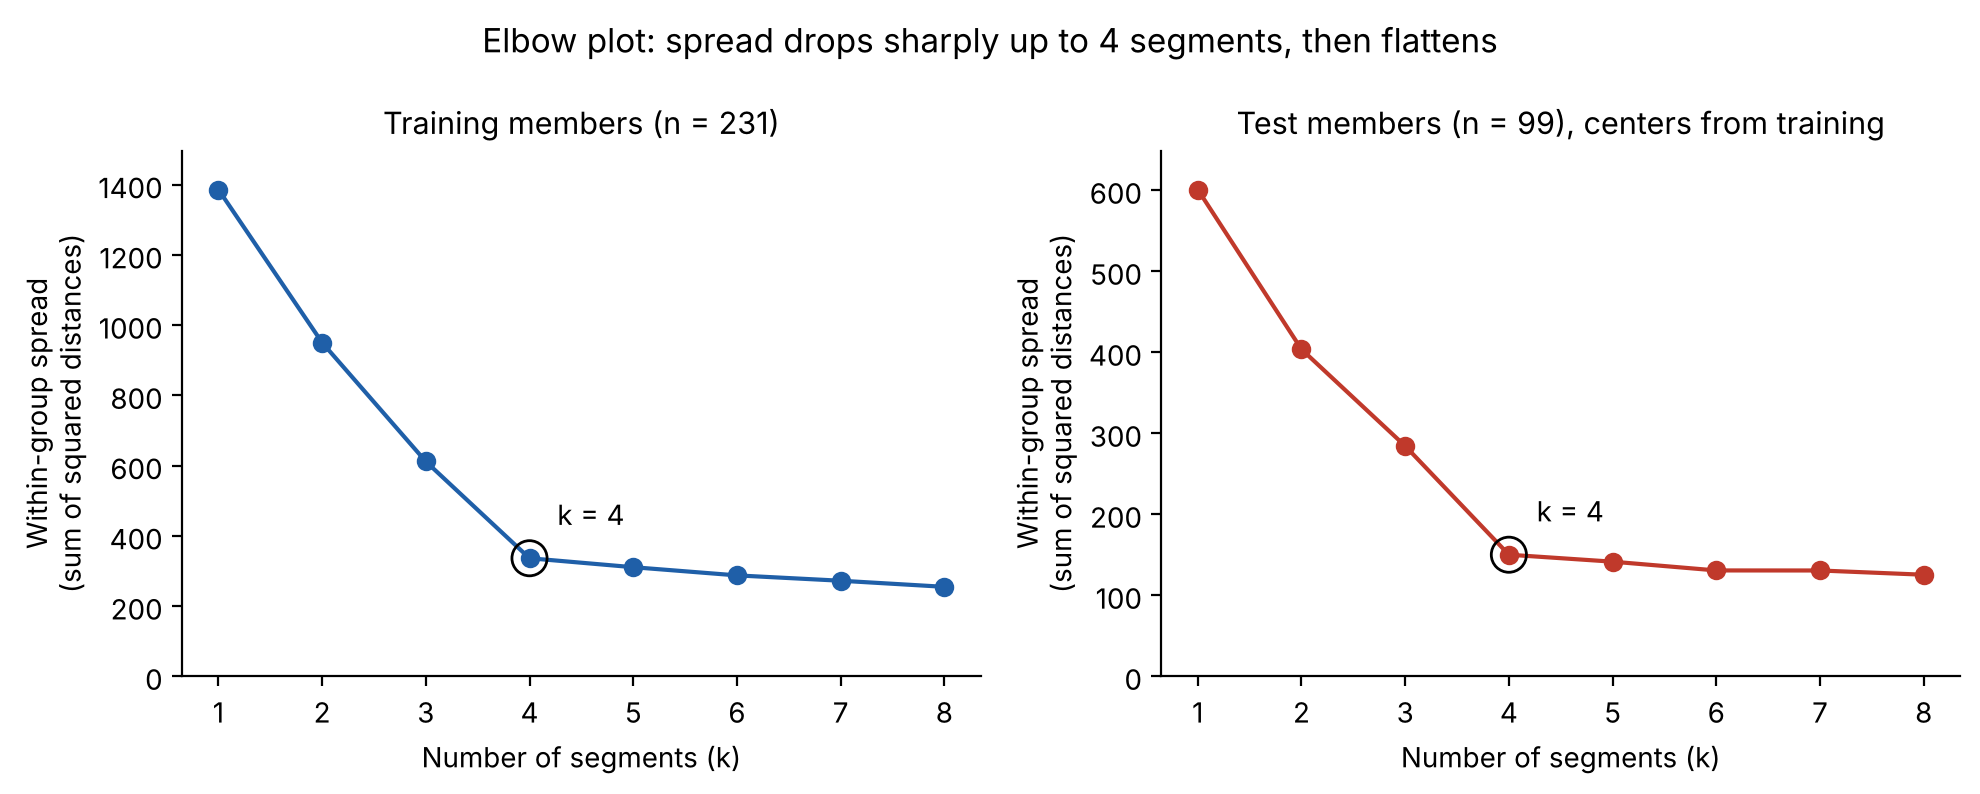

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, vals, title, color in [
        (axes[0], train_spread, f"Training members (n = {len(train)})", "#1f5fa8"),
        (axes[1], test_spread, f"Test members (n = {len(test)}), centers from training", "#c0392b")]:
    ax.plot(range(1, 9), vals, marker="o", color=color)
    ax.scatter([K_CHOSEN], [vals[K_CHOSEN - 1]], s=160, facecolors="none", edgecolors="black", zorder=3)
    ax.annotate(f"k = {K_CHOSEN}", (K_CHOSEN, vals[K_CHOSEN - 1]), textcoords="offset points",
                xytext=(10, 12), fontsize=10)
    ax.set_xticks(range(1, 9))
    ax.set_xlabel("Number of segments (k)")
    ax.set_ylabel("Within-group spread\n(sum of squared distances)")
    ax.set_title(title, fontsize=11)
    ax.set_ylim(0, max(vals) * 1.08)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Elbow plot: spread drops sharply up to 4 segments, then flattens", fontsize=12)
fig.tight_layout()
fig.savefig("figures/elbow_train_test.png", dpi=200)
plt.show()

**Choosing k:** each extra segment up to 4 cuts the training spread sharply (by about 436, 339 and 276); after 4 the drops are
small (about 26 or less). That bend is the elbow, so **k = 4**, which is also inside the 3 to 5 segments the operations lead asked for.

In [5]:
v1 = models[K_CHOSEN]
centers = pd.DataFrame(scaler.inverse_transform(v1.cluster_centers_), columns=FEATURES)

# k-means numbers its clusters arbitrarily; relabel A-D by average age so the labels are stable and easy to read
order = centers["age"].sort_values().index
label_of = {cluster: letter for cluster, letter in zip(order, "ABCD")}

gym["segment"] = [label_of[c] for c in v1.predict(scaler.transform(gym[FEATURES]))]
train_counts = pd.Series([label_of[c] for c in v1.labels_]).value_counts()

profile = centers.rename(index=label_of).sort_index().round(1)
profile["training members"] = train_counts.sort_index()
profile["all members"] = gym["segment"].value_counts().sort_index()
profile

,age,visits_per_month,avg_visit_minutes,classes_per_month,months_member,monthly_extras_spend,training members,all members
A,27.3,3.0,40.7,0.9,5.8,9.0,46,70
B,33.2,16.0,64.5,0.9,30.3,24.9,79,109
C,42.6,9.4,55.1,7.0,24.0,47.3,61,91
D,64.2,12.0,46.5,3.9,57.8,17.4,45,60


**The segments, from their centers (the average member in each):**

- **A**: youngest (about 27), newest (about 6 months), lightest users: about 3 visits and 1 class a month, about $9 a month on extras.
- **B**: early 30s, the heaviest gym users (about 16 visits a month, the longest visits at over an hour) but almost no classes; about $25 on extras.
- **C**: early 40s, class-focused (about 7 classes a month) and by far the biggest extras spenders (about $47 a month).
- **D**: oldest (about 64) and longest-standing (almost 5 years), visit often (about 12 a month), take some classes, moderate extras spend (about $17).

## 3. Evaluate fit on the test members

No refitting: each test member is assigned to the nearest **training** center (shown in the right panel of the elbow plot).

In [6]:
k1_test, kc_test = test_spread[0], test_spread[K_CHOSEN - 1]
k1_train, kc_train = train_spread[0], train_spread[K_CHOSEN - 1]
print(f"Test members, k = 1 (baseline): spread {k1_test:.1f}")
print(f"Test members, k = {K_CHOSEN} (v1):       spread {kc_test:.1f}")
print(f"  -> v1 cuts the test spread by {1 - kc_test / k1_test:.0%}")
print(f"(Training: {k1_train:.1f} -> {kc_train:.1f}, a {1 - kc_train / k1_train:.0%} cut)")
drops = -np.diff(test_spread)
print("\nTest-curve drops from each extra segment:", [round(float(x), 1) for x in drops])
print(f"The test curve also bends at k = {K_CHOSEN}: big drops up to {K_CHOSEN}, small drops after,")
print("so the segments found on training members hold up on members the model never saw.")

Test members, k = 1 (baseline): spread 600.7
Test members, k = 4 (v1):       spread 150.0
  -> v1 cuts the test spread by 75%
(Training: 1386.0 -> 336.0, a 76% cut)

Test-curve drops from each extra segment: [197.1, 119.4, 134.2, 8.6, 10.8, 0.1, 5.2]
The test curve also bends at k = 4: big drops up to 4, small drops after,
so the segments found on training members hold up on members the model never saw.


## 4. Make the decision

A segment gets the credit if, member by member, it makes the gym money: each member spending under $20 is worth +\$5,
each member spending \$20 or more costs \$10. That is positive when fewer than a third of the segment are \$20+ spenders.

In [7]:
gym["net_if_credit"] = np.where(gym["monthly_extras_spend"] >= SPEND_CUTOFF, NET_HIGH_SPENDER, NET_LOW_SPENDER)

by_seg = gym.groupby("segment").agg(
    members=("member_id", "size"),
    avg_extras_spend=("monthly_extras_spend", "mean"),
    under_20=("monthly_extras_spend", lambda s: int((s < SPEND_CUTOFF).sum())),
    net_if_credit=("net_if_credit", "sum"),
)
by_seg["share $20+"] = (1 - by_seg["under_20"] / by_seg["members"]).round(2)
by_seg["avg_extras_spend"] = by_seg["avg_extras_spend"].round(2)
by_seg["gets credit"] = by_seg["net_if_credit"] > 0
CREDIT_SEGMENTS = set(by_seg.index[by_seg["gets credit"]])
print("Segments that get the credit:", sorted(CREDIT_SEGMENTS))
by_seg

Segments that get the credit: ['A']


,members,avg_extras_spend,under_20,net_if_credit,share $20+,gets credit
segment,,,,,,
A,70,9.30,59,185,0.16,True
B,109,24.60,43,-445,0.61,False
C,91,46.93,1,-895,0.99,False
D,60,16.35,37,-45,0.38,False


In [8]:
def segment_and_credit(member, model=v1, scaler=scaler):
    """member: dict with the six feature columns. Returns (segment letter, gets credit True/False)."""
    row = scaler.transform(pd.DataFrame([member])[FEATURES])
    seg = label_of[model.predict(row)[0]]
    return seg, seg in CREDIT_SEGMENTS

new_member = dict(age=30, visits_per_month=4, avg_visit_minutes=42, classes_per_month=1,
                  months_member=5, monthly_extras_spend=10)
seg, credit = segment_and_credit(new_member)
print(f"New member -> segment {seg}, {'gets' if credit else 'does not get'} the credit")

New member -> segment A, gets the credit


## 5. Quantify it

Monthly net from the credit, applied member by member to all 330 members.

In [9]:
baseline_net = gym["net_if_credit"].sum()
v1_net = gym.loc[gym["segment"].isin(CREDIT_SEGMENTS), "net_if_credit"].sum()
n_credit = gym["segment"].isin(CREDIT_SEGMENTS).sum()

value = pd.DataFrame({
    "members getting credit": [len(gym), n_credit],
    "credit cost per month ($)": [len(gym) * CREDIT_COST, n_credit * CREDIT_COST],
    "monthly net from credit ($)": [baseline_net, v1_net],
}, index=["Baseline: credit to everyone", f"v1: credit to segment {', '.join(sorted(CREDIT_SEGMENTS))} only"])
print(f"Improvement: ${v1_net - baseline_net:,} a month, about ${12 * (v1_net - baseline_net):,} a year")
value

Improvement: $1,385 a month, about $16,620 a year


,members getting credit,credit cost per month ($),monthly net from credit ($)
Baseline: credit to everyone,330,3300,-1200
v1: credit to segment A only,70,700,185


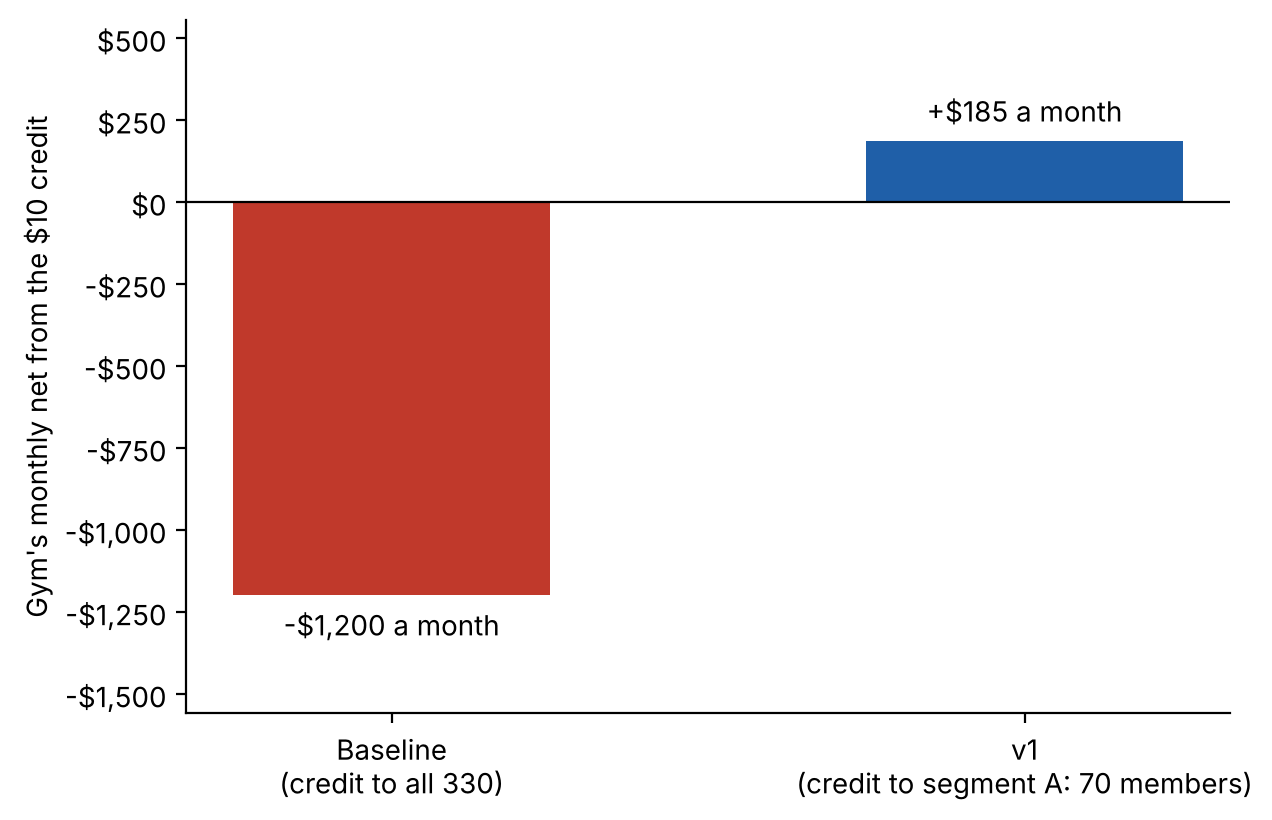

In [10]:
money = lambda v: f"-${abs(v):,.0f}" if v < 0 else f"+${v:,.0f}"
fig, ax = plt.subplots(figsize=(6.5, 4.2))
labels = ["Baseline\n(credit to all 330)", f"v1\n(credit to segment {', '.join(sorted(CREDIT_SEGMENTS))}: {n_credit} members)"]
vals = [baseline_net, v1_net]
bars = ax.bar(labels, vals, color=["#c0392b", "#1f5fa8"], width=0.5)
ax.axhline(0, color="black", lw=0.8)
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + (40 if v >= 0 else -40), f"{money(v)} a month",
            ha="center", va="bottom" if v >= 0 else "top", fontsize=10)
ax.set_ylabel("Gym's monthly net from the $10 credit")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: money(x).replace("+", "")))
ax.set_ylim(min(vals) * 1.3, max(vals) * 3)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("figures/monthly_net.png", dpi=200)
plt.show()